[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcostac/generative-networks/blob/main/vae/vae.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Training a VAE on MNIST

Tutorial for training a small Variational Autoencoder (VAE) to reconstruct and generate MNIST-like handwritten digits.

A VAE has two neural networks trained together:

- The **encoder** maps an image into a distribution over latent variables, represented by a mean and log-variance.
- The **decoder** samples from that latent distribution and tries to reconstruct the original image.

The reconstruction loss teaches the model to keep digit information, while the KL divergence regularizes the latent space so we can sample from it later.

## 0. Dependencies

In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

The defaults below are intentionally modest. You can increase `epochs` to get sharper reconstructions and cleaner samples.

In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "vae" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "vae" / "outputs" / "mnist_vae"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
image_channels = 1
image_size = 28
image_dim = image_channels * image_size * image_size
hidden_dim = 400
latent_dim = 20
epochs = 20
learning_rate = 1e-3

sample_every_epochs = 5
checkpoint_path = output_dir / "mnist_vae_checkpoint.pt"

## 3. Load MNIST

For this VAE we keep MNIST pixel values in `[0, 1]`. The decoder will produce logits, and `binary_cross_entropy_with_logits` will compare those logits against the original pixels.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), # Convert PIL image to tensor and scale pixel values to [0, 1].
])

train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=data_dir,
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

len(train_dataset), len(train_loader), len(test_dataset), len(test_loader)

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(60000, 469, 10000, 79)

Let's inspect a batch of real MNIST images.

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


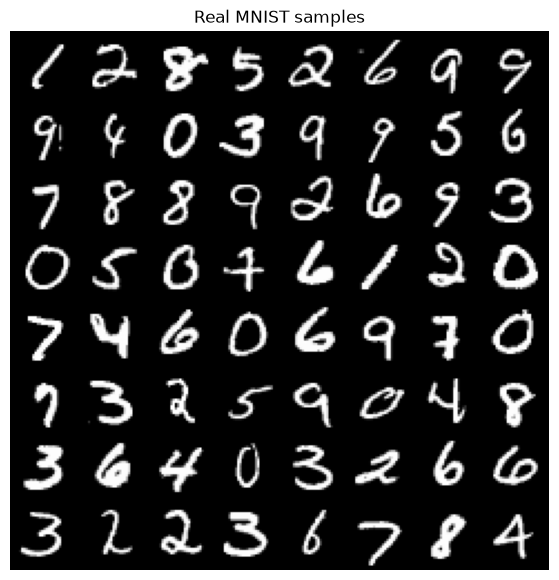

In [5]:
def show_image_grid(images, title=None, nrow=8):
    images = images.detach().cpu().clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


real_images, real_labels = next(iter(train_loader))
show_image_grid(real_images[:64], title="Real MNIST samples")

## 4. Define the VAE

The encoder outputs two vectors per sample: `mu` and `logvar`. Together they describe a diagonal Gaussian distribution in latent space.

During training we sample from that distribution using the reparameterization trick:

`z = mu + std * epsilon`

where `epsilon` is random noise. This keeps the sampling operation differentiable with respect to the encoder parameters.

In [6]:
class VAE(nn.Module):
    def __init__(self, image_dim=784, hidden_dim=400, latent_dim=20, image_channels=1, image_size=28):
        super().__init__()
        self.image_channels = image_channels
        self.image_size = image_size

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(image_dim, hidden_dim),
            nn.ReLU(inplace=True),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, image_dim),
        )

    def encode(self, images):
        hidden = self.encoder(images)
        return self.fc_mu(hidden), self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def decode(self, z):
        logits = self.decoder(z)
        return logits.view(z.size(0), self.image_channels, self.image_size, self.image_size)

    def forward(self, images):
        mu, logvar = self.encode(images)
        z = self.reparameterize(mu, logvar)
        reconstruction_logits = self.decode(z)
        return reconstruction_logits, mu, logvar

## 5. Define the VAE Objective

The VAE loss is the negative evidence lower bound, usually written as two terms:

1. **Reconstruction loss**: how well the decoded image matches the input image.
2. **KL divergence**: how close the encoder distribution is to the standard normal prior.

The KL term is what lets us later sample `z` directly from `N(0, I)` and get meaningful images.

In [7]:
def vae_loss(reconstruction_logits, images, mu, logvar):
    reconstruction_loss = F.binary_cross_entropy_with_logits(
        reconstruction_logits,
        images,
        reduction="sum",
    )
    kl_divergence = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    total_loss = reconstruction_loss + kl_divergence
    return total_loss, reconstruction_loss, kl_divergence

## 6. Initialize Model and Optimizer

This is a compact fully connected VAE. It is small enough to train quickly, so don't expect perfectly decoded samples.

In [8]:
vae = VAE(image_dim, hidden_dim, latent_dim, image_channels, image_size).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=learning_rate)

fixed_noise = torch.randn(64, latent_dim, device=device)
fixed_test_images, fixed_test_labels = next(iter(test_loader))
fixed_test_images = fixed_test_images[:16].to(device)

print(vae)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=400, bias=True)
    (2): ReLU(inplace=True)
  )
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=20, out_features=400, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=400, out_features=784, bias=True)
  )
)


## 7. Reconstruction and Sampling Helpers

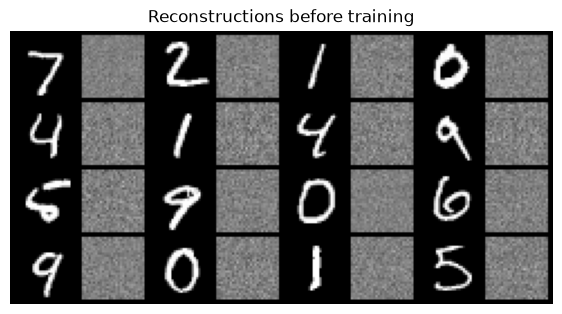

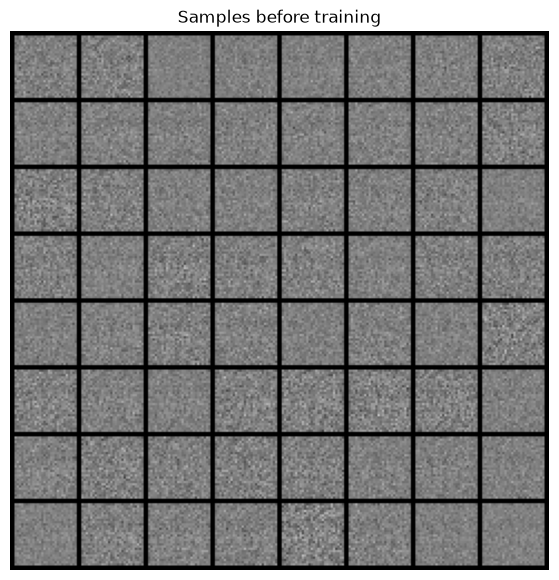

In [9]:
@torch.no_grad()
def reconstruct_images(vae, images=fixed_test_images, title="Reconstructions", save_path=None):
    vae.eval()
    reconstruction_logits, _, _ = vae(images)
    reconstructions = torch.sigmoid(reconstruction_logits)

    pairs = torch.empty(images.size(0) * 2, *images.shape[1:], device=images.device)
    pairs[0::2] = images
    pairs[1::2] = reconstructions

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(pairs.cpu().clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(pairs, title=title, nrow=8)


@torch.no_grad()
def sample_images(vae, noise=fixed_noise, title="Generated samples", save_path=None):
    vae.eval()
    logits = vae.decode(noise)
    images = torch.sigmoid(logits)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(images.cpu().clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")

    show_image_grid(images, title=title, nrow=8)


def save_checkpoint(epoch, history):
    torch.save(
        {
            "epoch": epoch,
            "vae_state_dict": vae.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "config": {
                "image_channels": image_channels,
                "image_size": image_size,
                "hidden_dim": hidden_dim,
                "latent_dim": latent_dim,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
            },
        },
        checkpoint_path,
    )


reconstruct_images(vae, title="Reconstructions before training")
sample_images(vae, title="Samples before training")

Before training, the reconstructions and samples should look like gray noise because the encoder and decoder weights are still random.

## 8. VAE Training Step

Each batch runs a standard autoencoder loop, plus the KL term:

1. Encode images into `mu` and `logvar`.
2. Sample latent vectors with the reparameterization trick.
3. Decode those latent vectors into reconstruction logits.
4. Minimize reconstruction loss plus KL divergence.

In [10]:
def run_epoch(vae, data_loader, train=True):
    vae.train(train)
    total_loss = 0.0
    total_reconstruction_loss = 0.0
    total_kl_divergence = 0.0
    total_images = 0

    for images, _ in data_loader:
        images = images.to(device, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)

        reconstruction_logits, mu, logvar = vae(images)
        loss, reconstruction_loss, kl_divergence = vae_loss(reconstruction_logits, images, mu, logvar)

        if train:
            loss.backward()
            optimizer.step()

        batch_size_seen = images.size(0)
        total_loss += loss.item()
        total_reconstruction_loss += reconstruction_loss.item()
        total_kl_divergence += kl_divergence.item()
        total_images += batch_size_seen

    return {
        "loss": total_loss / total_images,
        "reconstruction_loss": total_reconstruction_loss / total_images,
        "kl_divergence": total_kl_divergence / total_images,
    }


def train_one_epoch(epoch, vae, train_loader, test_loader):
    train_metrics = run_epoch(vae, train_loader, train=True)
    with torch.no_grad():
        test_metrics = run_epoch(vae, test_loader, train=False)

    return {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_reconstruction_loss": train_metrics["reconstruction_loss"],
        "train_kl_divergence": train_metrics["kl_divergence"],
        "test_loss": test_metrics["loss"],
        "test_reconstruction_loss": test_metrics["reconstruction_loss"],
        "test_kl_divergence": test_metrics["kl_divergence"],
    }

## 9. Train the VAE

Run this cell to train. The loss is reported in nats per image (one nat is equivalent to log(e) bits). Reconstructions should become readable first; sampling new images usually improves more slowly because they depend on the latent space matching the prior.

Epoch 001/020 | train loss: 163.96 | train recon: 147.98 | train KL: 15.97 | test loss: 126.74
Epoch 002/020 | train loss: 121.14 | train recon: 98.14 | train KL: 22.99 | test loss: 115.53
Epoch 003/020 | train loss: 114.53 | train recon: 90.05 | train KL: 24.48 | test loss: 111.90
Epoch 004/020 | train loss: 111.72 | train recon: 86.78 | train KL: 24.94 | test loss: 109.92
Epoch 005/020 | train loss: 110.04 | train recon: 84.83 | train KL: 25.21 | test loss: 108.63


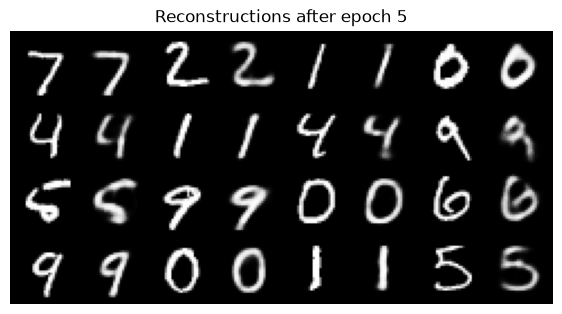

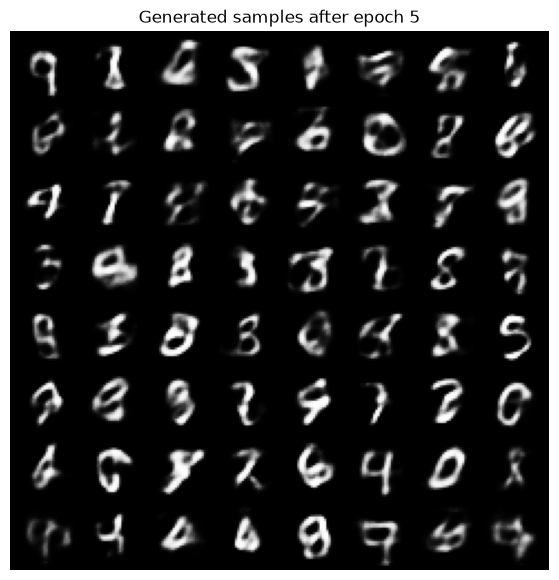

Epoch 006/020 | train loss: 108.90 | train recon: 83.56 | train KL: 25.34 | test loss: 108.00
Epoch 007/020 | train loss: 108.04 | train recon: 82.62 | train KL: 25.42 | test loss: 107.13
Epoch 008/020 | train loss: 107.46 | train recon: 81.93 | train KL: 25.52 | test loss: 106.73
Epoch 009/020 | train loss: 106.90 | train recon: 81.35 | train KL: 25.55 | test loss: 106.25
Epoch 010/020 | train loss: 106.47 | train recon: 80.88 | train KL: 25.59 | test loss: 105.92


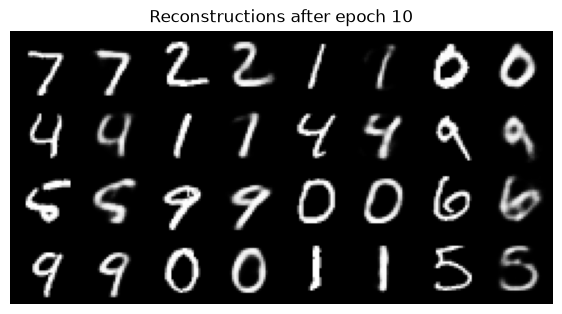

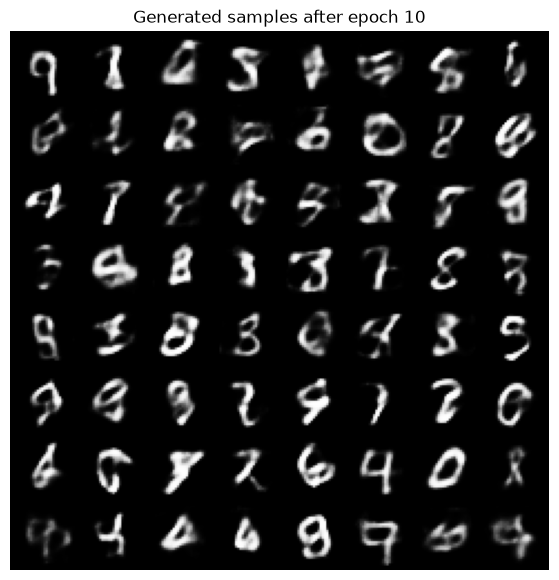

Epoch 011/020 | train loss: 106.12 | train recon: 80.50 | train KL: 25.62 | test loss: 105.83
Epoch 012/020 | train loss: 105.82 | train recon: 80.17 | train KL: 25.64 | test loss: 105.53
Epoch 013/020 | train loss: 105.56 | train recon: 79.91 | train KL: 25.64 | test loss: 105.17
Epoch 014/020 | train loss: 105.32 | train recon: 79.65 | train KL: 25.67 | test loss: 105.15
Epoch 015/020 | train loss: 105.11 | train recon: 79.44 | train KL: 25.67 | test loss: 104.86


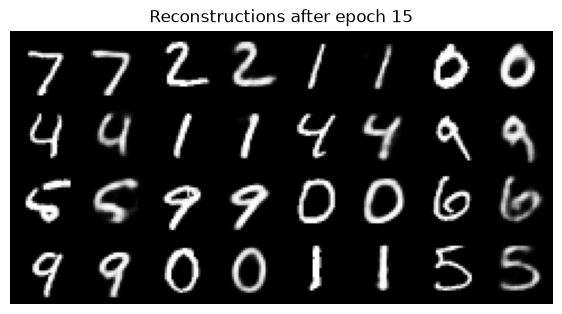

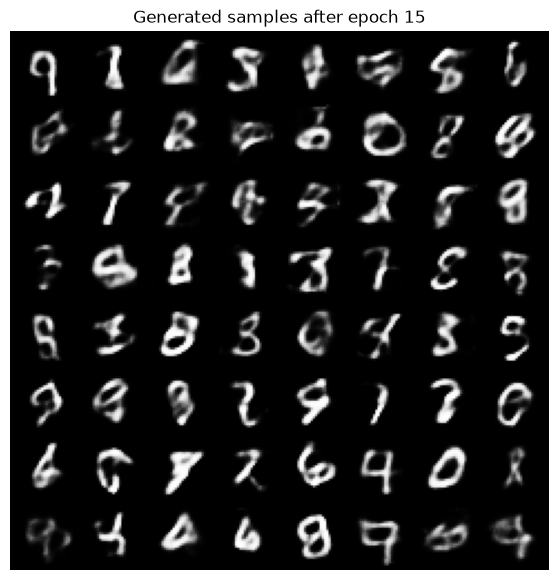

Epoch 016/020 | train loss: 104.94 | train recon: 79.25 | train KL: 25.69 | test loss: 104.58
Epoch 017/020 | train loss: 104.76 | train recon: 79.06 | train KL: 25.70 | test loss: 104.34
Epoch 018/020 | train loss: 104.59 | train recon: 78.90 | train KL: 25.69 | test loss: 104.47
Epoch 019/020 | train loss: 104.43 | train recon: 78.72 | train KL: 25.71 | test loss: 104.27
Epoch 020/020 | train loss: 104.32 | train recon: 78.61 | train KL: 25.70 | test loss: 104.12


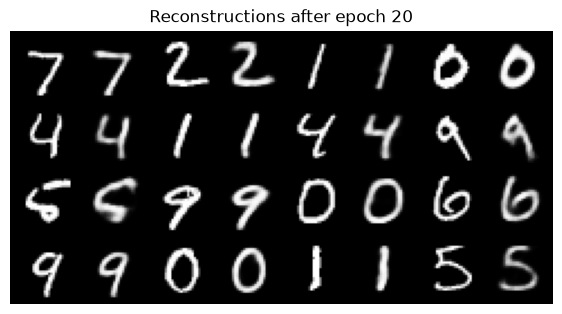

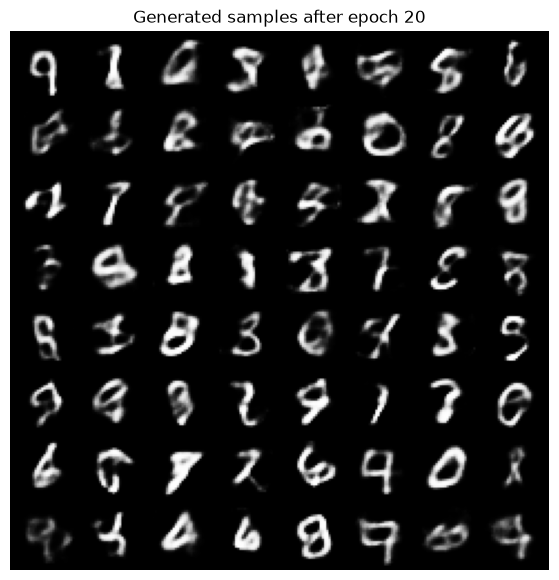

Saved latest checkpoint to: /home/nahuel/generative-networks/vae/outputs/mnist_vae/mnist_vae_checkpoint.pt


In [11]:
history = []

for epoch in range(1, epochs + 1):
    metrics = train_one_epoch(epoch, vae, train_loader, test_loader)
    history.append(metrics)

    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"train loss: {metrics['train_loss']:.2f} | "
        f"train recon: {metrics['train_reconstruction_loss']:.2f} | "
        f"train KL: {metrics['train_kl_divergence']:.2f} | "
        f"test loss: {metrics['test_loss']:.2f}"
    )

    if epoch % sample_every_epochs == 0 or epoch == epochs:
        reconstruction_path = output_dir / f"reconstructions_epoch_{epoch:03d}.png"
        sample_path = output_dir / f"samples_epoch_{epoch:03d}.png"
        reconstruct_images(vae, title=f"Reconstructions after epoch {epoch}", save_path=reconstruction_path)
        sample_images(vae, title=f"Generated samples after epoch {epoch}", save_path=sample_path)

    save_checkpoint(epoch, history)

print(f"Saved latest checkpoint to: {checkpoint_path}")

## 10. Plot Training Curves

The total loss combines reconstruction and KL terms, so it is useful to plot the parts separately. A good run usually lowers reconstruction loss while keeping a nonzero KL term.

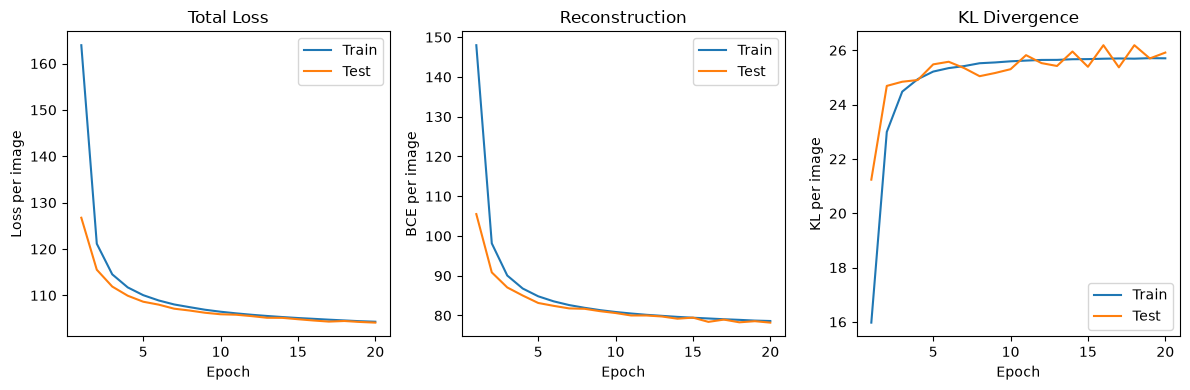

In [17]:
epochs_seen = [row["epoch"] for row in history]

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(epochs_seen, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Loss per image")
plt.legend()
plt.title("Total Loss")

plt.subplot(1, 3, 2)
plt.plot(epochs_seen, [row["train_reconstruction_loss"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_reconstruction_loss"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("BCE per image")
plt.legend()
plt.title("Reconstruction")

plt.subplot(1, 3, 3)
plt.plot(epochs_seen, [row["train_kl_divergence"] for row in history], label="Train")
plt.plot(epochs_seen, [row["test_kl_divergence"] for row in history], label="Test")
plt.xlabel("Epoch")
plt.ylabel("KL per image")
plt.legend()
plt.title("KL Divergence")

plt.tight_layout()
plt.show()

## 11. Reconstruct Test Digits

Each pair below shows an original test image followed by its reconstruction.

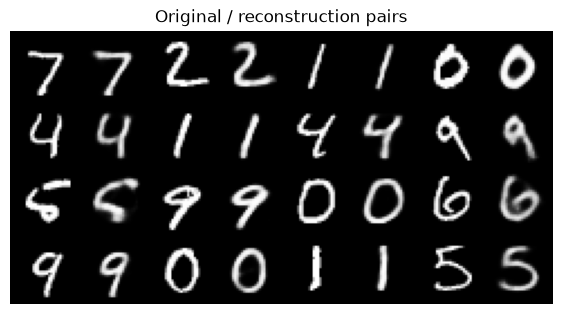

In [18]:
test_images, test_labels = next(iter(test_loader))
reconstruct_images(vae, images=test_images[:16].to(device), title="Original / reconstruction pairs")

## 12. Generate New Digits

After training, sample latent vectors from the standard normal prior and decode them into images.

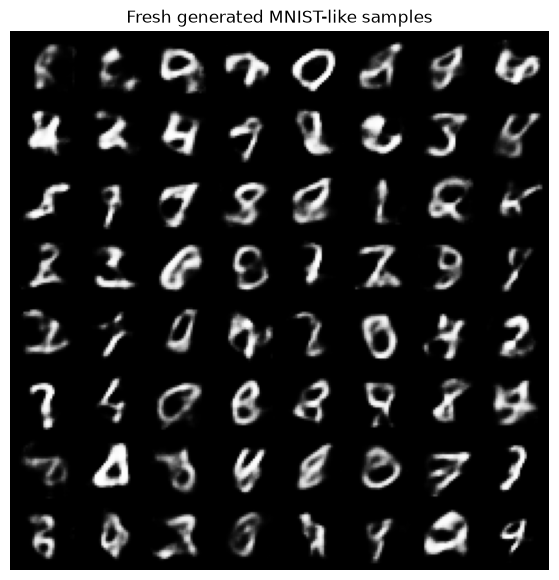

In [19]:
new_noise = torch.randn(64, latent_dim, device=device)
sample_images(vae, noise=new_noise, title="Fresh generated MNIST-like samples")

## 13. Latent Space Interpolation

A good latent space should change smoothly. Here we encode two real digits, interpolate between their latent means, and decode the path.

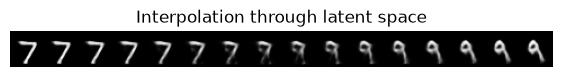

In [20]:
@torch.no_grad()
def interpolate_between_images(vae, images, start_index=0, end_index=1, steps=16):
    vae.eval()
    images = images.to(device)
    mu, _ = vae.encode(images)
    z_start = mu[start_index:start_index + 1]
    z_end = mu[end_index:end_index + 1]
    weights = torch.linspace(0, 1, steps, device=device).view(steps, 1)
    z = (1 - weights) * z_start + weights * z_end
    logits = vae.decode(z)
    generated = torch.sigmoid(logits)
    show_image_grid(generated, title="Interpolation through latent space", nrow=steps)


test_images, test_labels = next(iter(test_loader))
interpolate_between_images(vae, test_images, start_index=0, end_index=7, steps=16)

## 14. Loading a Saved Checkpoint

Use this cell later if you restart the kernel and want to resume from the latest saved model.

In [16]:
# checkpoint = torch.load(checkpoint_path, map_location=device)
# vae.load_state_dict(checkpoint["vae_state_dict"])
# optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# history = checkpoint["history"]
# print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")

## 15. Things to Try

- Train for more epochs and compare reconstructions with prior samples.
- Change `latent_dim` to 2 and visualize the learned latent coordinates by digit label.
- Increase `hidden_dim` or replace the fully connected layers with convolutional layers.
- Add a `beta` multiplier to the KL term to train a beta-VAE.
- Compare samples from random `z` against interpolations between encoded real images.

## Troubleshooting

- If generated samples are blurry, train longer or use a convolutional decoder.
- If reconstructions are good but random samples look poor, the latent distribution may not match the prior well enough. Try increasing the KL weight gradually or training longer.
- If you run out of GPU memory, lower `batch_size`.